In [1]:
import os, glob, json, shutil
found = [r for r, d, f in os.walk('/kaggle/input', followlinks=True) if 'pyproject.toml' in f]
shutil.copytree(found[0], '/kaggle/working/mhs-project', dirs_exist_ok=True)
os.chdir('/kaggle/working/mhs-project')
!pip install -q -e ".[acquire]"
!mhs label-aid --help | grep -q steep && echo "v11 loaded" || echo "OLD VERSION - update the code dataset"
if not os.path.exists('data/chamoli/t1.tif'):
    !mhs acquire configs/chamoli.yaml --out data/chamoli > /dev/null
poly = glob.glob('/kaggle/input/**/labels.geojson', recursive=True)[0]
feats = json.load(open(poly))['features']
print('labels file:', poly, '| polygons:', len(feats))
print('rock polygons:', sum(str(f['properties'].get('class')).lower() == 'rock' for f in feats))
!mhs rasterize-labels configs/chamoli.yaml --polygons {poly} --out data/chamoli/labels.tif

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for mhs (pyproject.toml) ... done
v11 loaded
labels file: /kaggle/input/datasets/ilikesomeone/chamoli-labels/labels.geojson | polygons: 63
rock polygons: 10
{
  "out": "data/chamoli/labels.tif",
  "polygons": 63,
  "pixels_per_class": {
    "t1": {
      "background": 9955,
      "water": 0,
      "snow_ice": 20450,
      "rock": 4465,
      "soil": 18962,
      "debris": 0
    },
    "t2": {
      "background": 10604,
      "water": 0,
      "snow_ice": 20487,
      "rock": 10980,
      "soil": 30332,
      "debris": 2077
    }
  }
}
labelled pixels per split strip (t1 + t2):
  train      background 9126  water 0  snow_ice 27573  rock 13910  soil 38311  debris 2077
  validation background 10208  water 0  snow_ice 2042  rock 0  soil 5698  debris 0
  test       b

--- seed 0 ---
seed 0: best epoch 16, test macro F1 0.621
--- seed 1 ---
seed 1: best epoch 21, test macro F1 0.671
--- seed 2 ---
seed 2: best epoch 1, test macro F1 0.651

U-Net (3 seeds) vs rule baseline, held-out test strip
class           support   U-Net F1 mean ± sd       min-max  baseline F1
background         1225       0.982 ± 0.018  0.961-0.994        0.713
snow_ice          11322       0.997 ± 0.005  0.991-1.000        1.000
rock               1535       0.301 ± 0.032  0.275-0.337        0.354
soil               5285       0.311 ± 0.097  0.199-0.377        0.009
macro_f1                      0.648 ± 0.025  0.621-0.671        0.519
overall_accuracy                0.740 ± 0.020  0.726-0.763        0.695
run directory: runs/chamoli_unet
illumination and cast shadows ...
routing grid ...
surface mapping with U-Net models/bench/seed_0/unet.pt
   illumination gate removed 9.15 km2 of class change
   ignored transitions [['rock', 'soil']]: 3.17 km2 removed
302 candidate source zone

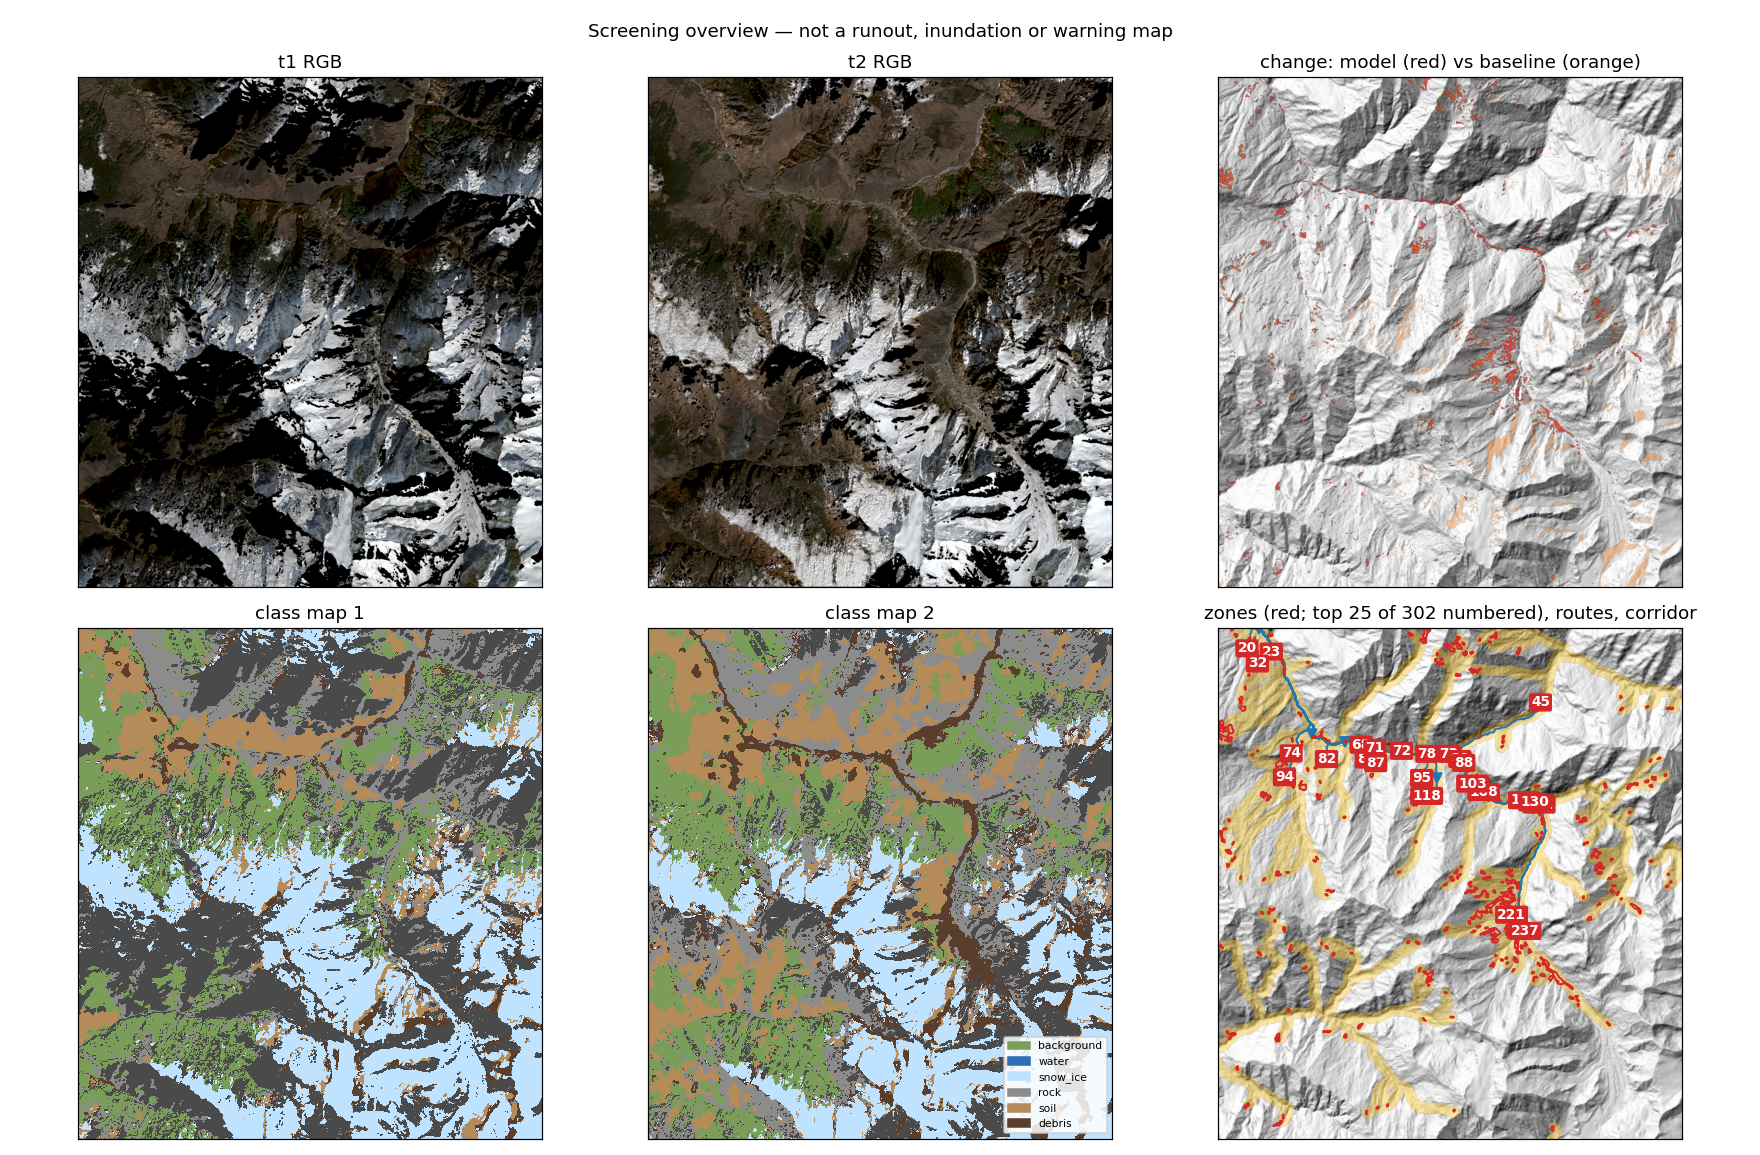

total 11M
-rw-r--r-- 1 root root 2.7K Nov  1 01:52 benchmark.json
drwxr-xr-x 3 root root 4.0K Nov  1 01:52 chamoli_unet
-rw-r--r-- 1 root root  11M Nov  1 01:52 chamoli_unet.zip


In [2]:
!mhs benchmark configs/chamoli.yaml --out models/bench --seeds 0 1 2
!sed -i 's#^  assets:.*#  assets: null#' configs/chamoli.yaml
!mhs run configs/chamoli.yaml --model models/bench/seed_0/unet.pt --out runs/chamoli_unet
from IPython.display import Image, display
display(Image('runs/chamoli_unet/overview.png'))
!cd runs && zip -qr chamoli_unet.zip chamoli_unet && cp ../models/bench/benchmark.json . && ls -lh